# Inspect and assess a Fe-Cr-Ni surrogate

What data were retained, where can the surrogate be used, and how do its predictions
compare with new calculations from the same source? These questions differ from
conservation and from agreement with experiments. We keep them separate below.

Run cells from top to bottom in the `kawin` environment with the package installed.
Start the kernel in this examples directory or at the extraction repository root.
Each notebook is independent; no earlier notebook needs to have been run.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt

from moving_boundary.providers.pycalphad import create_pycalphad_thermodynamics_source
from moving_boundary.sampling import ternary_simplex_points
from moving_boundary.surrogates import TernaryMovingBoundaryThermodynamicsSurrogate
import numpy as np

## Define the couple

These are the introductory notebook's couple B inputs [1, 2]. Phases run left to
right; FE is dependent and composition pairs are `[X_CR, X_NI]` mole fractions.
Temperature is in kelvin and diffusivity matrices are in square metres per second.
The two initial far fields supply the coverage-check points below.

The adapted open MatCalc database [3, 4] is bundled beside these notebooks;
[the README](README.md#open-fe-cr-ni-database-and-surrogate-workflow) documents
its attribution and licence. Edit `database` if using another file location.

In [2]:
database = Path("FeCrNi_MatCalc_open.tdb")  # kernel starts beside this notebook
if not database.is_file():
    database = Path("packages/moving-boundary/examples") / database  # repository root

elements = ["FE", "CR", "NI"]
independent = ["CR", "NI"]
phases = ["BCC_A2", "FCC_A1"]
temperature = 1373.0
left_composition = [0.39696, 0.0001]   # BCC far field [2, Table 3]
right_composition = [0.139297, 0.142387]  # FCC far field [2, Table 3]

## Sample the open database

Restrict equilibrium to BCC_A2 and FCC_A1. The interior probe seeds a family
of 17 tie lines; it is not the initial bulk composition. The bulk grid has
spacing 0.05. Unusable bulk matrices are omitted, and `validity_policy="raise"`
rejects unsupported queries. These demonstration settings are not converged.
This cell samples afresh; progress output is collapsed in the saved notebook.

In [3]:
source = create_pycalphad_thermodynamics_source(
    database, elements, phases, use_default_phases=False, g_offset=0.0,
)

bulk_points = ternary_simplex_points(spacing=0.05)
surrogate = TernaryMovingBoundaryThermodynamicsSurrogate.from_database(
    thermodynamics=source,
    elements=elements,
    phases=phases,
    tieline_phases=phases,
    temperature=temperature,
    probe_point=[0.45, 0.21],
    probe_samples_per_side=8,
    precipitate_phase=phases[1],
    diffusivity_bulk_points=bulk_points,
    diffusivity_interpolation="simplex_positive_2x2",
    skip_failed_bulk_calculations=True,
    drop_invalid_bulk_matrices=True,
    validity_policy="raise",
    min_composition=1.0e-10,
)

for phase in phases:
    compositions, matrices = surrogate.get_diffusivity_samples(phase)
    print(f"{phase}: {len(compositions)} retained bulk diffusivity samples")

Initial scan direction: [0.59321673 0.8050428 ]
Initial seed_sample: {'probe': array([0.45, 0.21]), 'endpoints': (array([0.57577713, 0.11731785]), array([0.35589239, 0.27934564])), 'diffusivities': (array([[1.51312606e-13, 1.69738852e-13],
       [3.93063828e-14, 9.29449039e-14]]), array([[ 3.83127736e-15, -1.42282854e-15],
       [-9.43938713e-16,  4.74858267e-15]])), 'midpoint': array([0.46583476, 0.19833174])}
totalNumCalcs: -1


i+1: 32
j: 14
scan direction after neg scan: [0.59321673 0.8050428 ]
seed_sample after neg scan: {'probe': array([0.45, 0.21]), 'endpoints': (array([0.57577713, 0.11731785]), array([0.35589239, 0.27934564])), 'diffusivities': (array([[1.51312606e-13, 1.69738852e-13],
       [3.93063828e-14, 9.29449039e-14]]), array([[ 3.83127736e-15, -1.42282854e-15],
       [-9.43938713e-16,  4.74858267e-15]])), 'midpoint': array([0.46583476, 0.19833174])}
totalNumCalcs: -1


i+1: 24
j: 14
scan direction after pos scan: [0.59321673 0.8050428 ]
seed_sample after pos scan: {

Resampling tieline data: 100%|██████████| 17/17 [00:00<00:00, 42.65it/s]


totalNumCalcs: -1


Sampling bulk diffusivity for phase FCC_A1: 100%|██████████| 231/231 [00:01<00:00, 214.19it/s]


BCC_A2: 248 retained bulk diffusivity samples
FCC_A1: 248 retained bulk diffusivity samples


## Inspect the actual training data

A tie line joins the BCC and FCC compositions in local equilibrium. Bulk plots
show the retained samples, not fitted predictions; colour is the CR-CR matrix
entry in square metres per second. Missing requested points need investigation,
not an assumption that the whole composition triangle is supported.

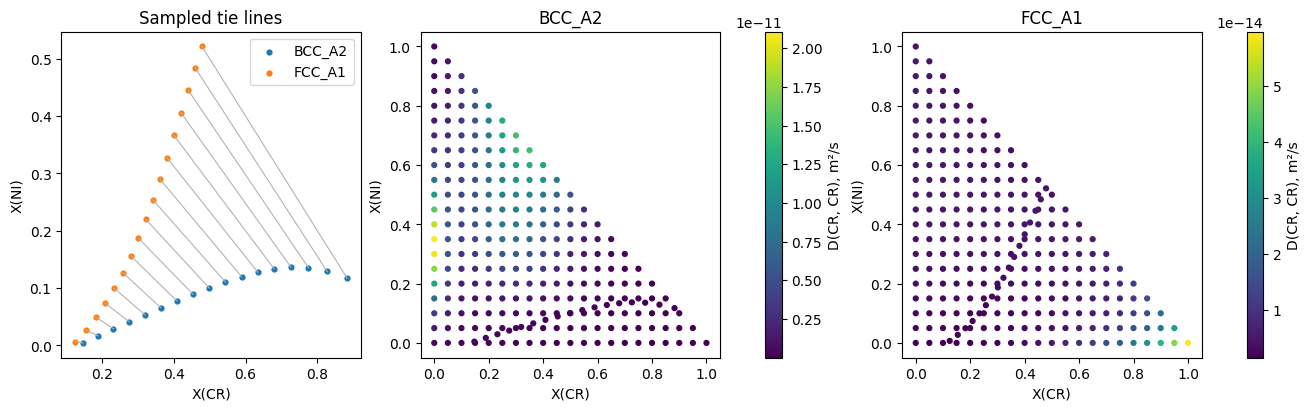

In [ ]:
#NOTES is it possible to have interactive plotly plots display natively in an ipynb file? If so that could be nice to have for these visualizations
fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)
left = surrogate.tieline_compositions[phases[0]]
right = surrogate.tieline_compositions[phases[1]]
for a, z in zip(left, right):
    axes[0].plot([a[0], z[0]], [a[1], z[1]], color="0.7", linewidth=0.8)
for phase, points in zip(phases, (left, right)):
    axes[0].scatter(points[:, 0], points[:, 1], s=12, label=phase)
axes[0].set_title("Sampled tie lines")
axes[0].legend()
for ax, phase in zip(axes[1:], phases):
    compositions, matrices = surrogate.get_diffusivity_samples(phase)
    points = ax.scatter(compositions[:, 0], compositions[:, 1], c=matrices[:, 0, 0], s=12)
    fig.colorbar(points, ax=ax, label="D(CR, CR), m²/s")
    ax.set_title(phase)
for ax in axes:
    ax.set(xlabel="X(CR)", ylabel="X(NI)")
plt.show()

## Inspect sampling outcomes and coverage

Construction records explain what was attempted, accepted, or rejected. Hull
membership tests geometric support of the retained samples; it does not establish
accuracy or rule out invalid regions inside that hull. Here we check the two
initial far-field compositions in their respective phases, not an entire trajectory.

In [ ]:
#NOTES is "equilibrium - invalid" capturing the invalid eqs that were used when finding the extend of the terminal tielines because if so it's a bit misleading because the user might think they were intended to succeed
from moving_boundary import surrogate_diagnostics as diagnostics
from moving_boundary.run_diagnostics import evaluate_bulk_coverage

construction = diagnostics.evaluate_surrogate_construction_diagnostics(surrogate)
for (kind, phase, outcome), count in sorted(construction["counts"].items()):
    print(f"{kind:20s} {phase:8s} {outcome:22s} {count}")
coverage = evaluate_bulk_coverage(surrogate, {
    phases[0]: np.asarray([left_composition]), phases[1]: np.asarray([right_composition]),
})
print("Initial far-field points outside sample hull:", {p: r["outside"] for p, r in coverage.items()})

equilibrium                   invalid                14
equilibrium                   success                88
kinetics             BCC_A2   success                319
kinetics             FCC_A1   success                319
Initial far-field points outside sample hull: {'BCC_A2': 0, 'FCC_A1': 0}


## Leave one retained sample out

At most 20 evenly distributed samples per phase are excluded in turn and predicted
from a refit. This is **internal cross-validation**, not a comparison with fresh
source data. Removing a hull vertex may leave insufficient support; those cases
and invalid predictions are reported separately, never counted as zero error.

  0%|          | 0/248 [00:00<?, ?it/s]

100%|██████████| 248/248 [00:04<00:00, 49.80it/s]

BCC_A2 {'sample_count': 248, 'failure_count': 0, 'nearest_fallback_count': 0, 'insufficient_fit_support_count': 4, 'invalid_prediction_count': 0, 'mean_matrix_relative_error': 0.08046690828654021, 'max_matrix_relative_error': 0.9863350808050928}
FCC_A1 {'sample_count': 248, 'failure_count': 0, 'nearest_fallback_count': 0, 'insufficient_fit_support_count': 4, 'invalid_prediction_count': 0, 'mean_matrix_relative_error': 0.04483028891538385, 'max_matrix_relative_error': 0.34357534501718856}


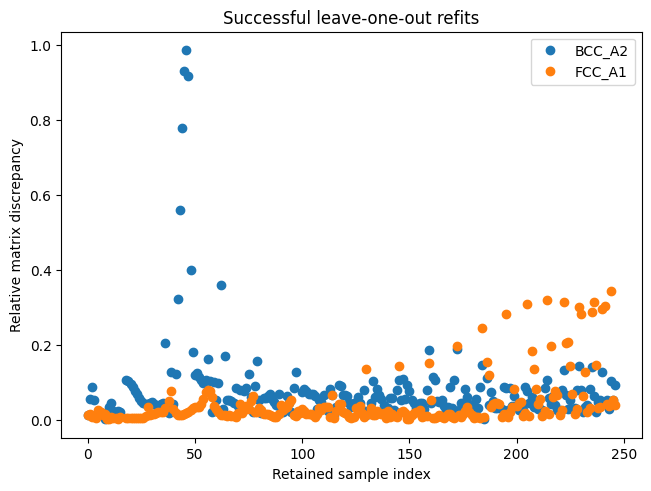

In [ ]:
#NOTES I think we might want to show this on a ternary plot (ideally as a hoverable plotly plot, see NOTES two cells above). I think I'd also like to change the downsampling from just a (somewhat) random 20 points to either a more spatially aware downsampling (like taking points on a coarser grid spacing but which is a muliple of the original so that it is a subset of the original points) or getting rid of the downsampling for this example since doing all 248 points only takes ~10 seconds
sample_indices = {}
for phase in phases:
    count = len(surrogate.get_diffusivity_samples(phase)[0])
    sample_indices[phase] = np.unique(np.linspace(0, count - 1, min(20, count)).round().astype(int))
loo = diagnostics.evaluate_diffusivity_leave_one_out(surrogate, sample_indices=sample_indices)

fig, ax = plt.subplots(constrained_layout=True)
for phase, report in loo["phase_reports"].items():
    usable = (report["prediction_status"] == "ok") & report["predicted_valid"]
    usable &= np.isfinite(report["matrix_relative_error"])
    print(phase, report["summary"])
    ax.plot(report["sample_indices"][usable], report["matrix_relative_error"][usable], "o", label=phase)
ax.set(xlabel="Retained sample index", ylabel="Relative matrix discrepancy", title="Successful leave-one-out refits")
ax.legend()
plt.show()

## Compare with fresh queries of the same source

We use the existing workflow's bounded test locations. Tie-line endpoint queries
include training locations and intermediate points; bulk query axes lie between
the requested grid nodes. Actual membership is checked against retained samples.
Training agreement mostly checks reproduction of stored values. Held-out
comparisons probe approximation between samples; neither establishes physical truth.

Reports retain backend failures. The summary below excludes failed or invalid
comparisons from error averages and prints the excluded count explicitly.

In [10]:
tieline_report = diagnostics.evaluate_tieline_diagnostics(
    surrogate, thermodynamics=source, eta_count=8, on_truth_error="record",
)
fresh = diagnostics.evaluate_diffusivity_diagnostics(
    surrogate, thermodynamics=source, interface_eta_count=6,
    bulk_axes=((0.175, 0.325, 0.475), (0.025, 0.125, 0.275)), on_truth_error="record",
)
print("Fresh tie-line query failures:", len(tieline_report["failures"]))
for phase, errors in tieline_report["truth"]["endpoint_error_norm"].items():
    for label, group in (("training", tieline_report["training_mask"]),
                         ("held-out", ~tieline_report["training_mask"])):
        selected = np.asarray(errors)[group]
        usable = selected[np.isfinite(selected)]
        mean = f"{usable.mean():.3g}" if len(usable) else "no usable comparisons"
        print(f"{phase} tie-line {label}: {len(usable)}/{len(selected)} usable; mean endpoint distance {mean}")

fresh_summary = []
for context in ("interface", "bulk"):
    for phase, report in fresh[context]["phases"].items():
        training = (report["training_mask"] if context == "interface"
                    else report["nearest_training_distance"] <= 1.0e-12)
        errors = report["truth"]["matrix_relative_error"]
        valid = report["valid"] & report["truth"]["valid"] & np.isfinite(errors)
        print(f"{phase} {context}: {len(report['failures'])} backend query failures")
        for label, group in (("training", training), ("held-out", ~training)):
            usable = group & valid
            requested, compared = int(group.sum()), int(usable.sum())
            mean = float(errors[usable].mean()) if compared else None
            fresh_summary.append((phase, context, label, requested, compared, requested - compared, mean))
print("phase, context, group, requested, compared, excluded, mean relative matrix discrepancy")
for row in fresh_summary:
    print(row)

Evaluating ground-truth tie-lines: 100%|██████████| 8/8 [00:00<00:00, 58.13it/s]
Evaluating ground-truth matrices of tie-line endpoints (BCC_A2): 100%|██████████| 6/6 [00:00<00:00, 84.37it/s]
Evaluating ground-truth matrices of tie-line endpoints (FCC_A1): 100%|██████████| 6/6 [00:00<00:00, 118.61it/s]
Evaluating ground-truth matrices of bulk points (BCC_A2): 100%|██████████| 9/9 [00:00<00:00, 152.41it/s]
Evaluating ground-truth matrices of bulk points (FCC_A1): 100%|██████████| 9/9 [00:00<00:00, 166.29it/s]

Fresh tie-line query failures: 0
BCC_A2 tie-line training: 2/2 usable; mean endpoint distance 0
BCC_A2 tie-line held-out: 6/6 usable; mean endpoint distance 0.000199
FCC_A1 tie-line training: 2/2 usable; mean endpoint distance 0
FCC_A1 tie-line held-out: 6/6 usable; mean endpoint distance 0.000157
BCC_A2 interface: 0 backend query failures
FCC_A1 interface: 0 backend query failures
BCC_A2 bulk: 0 backend query failures
FCC_A1 bulk: 0 backend query failures
phase, context, group, requested, compared, excluded, mean relative matrix discrepancy
('BCC_A2', 'interface', 'training', 2, 2, 0, 9.541156770537643e-16)
('BCC_A2', 'interface', 'held-out', 4, 4, 0, 0.0037198512633814787)
('FCC_A1', 'interface', 'training', 2, 2, 0, 2.634987801350382e-15)
('FCC_A1', 'interface', 'held-out', 4, 4, 0, 0.0018567461826359969)
('BCC_A2', 'bulk', 'training', 0, 0, 0, None)
('BCC_A2', 'bulk', 'held-out', 9, 9, 0, 0.049310310604836156)
('FCC_A1', 'bulk', 'training', 0, 0, 0, None)
('FCC_A1', 'bulk', 'held-o

## What to investigate next

Locate rejected samples and large discrepancies before increasing resolution.
Try a denser bulk grid or more tie lines, rerun all following cells, and compare
reports at the same held-out points. A consistency flag is a diagnostic clue,
not an accuracy certificate. For simulation sensitivity, continue to
[the resolution study](fecrni_resolution_study.ipynb).

## References

1. M. Kajihara, C.-B. Lim, M. Kikuchi, "Experimental study on dissolution of alpha
   phase in gamma/alpha/gamma diffusion couples of the Fe-Cr-Ni system,"
   *ISIJ International* 33 (1993) 498-507. Source of the couples and annealing temperature.
2. B.-J. Lee, K. H. Oh, "Numerical treatment of the moving interface in diffusional
   reactions," *Z. Metallkd.* 87 (1996) 195-204. Couple B compositions and dimensions
   from Table 3, originating in [1].
3. E. Povoden-Karadeniz, MatCalc thermodynamic steel database mc_fe, release 2.060,
   TU Wien, [MatCalc open databases](https://www.matcalc.at/index.php/databases/open-databases).
   Thermodynamic parameters in the bundled adapted excerpt; ODbL 1.0 / DbCL 1.0.
4. E. Povoden-Karadeniz, MatCalc diffusion mobility database for steel (mc_fe), TU Wien,
   same source and licence as [3]. Mobility parameters in the excerpt match releases
   2.012, 2.015, and 2.016; no single release is identified.